# Chapter 62: Structural Transformation, Dual Economies, and Migration

This notebook reruns four worked examples from the chapter: an inverted U in income dispersion (Kuznets curve), a shift-share split of a productivity gain, Baumol cost disease for a concert, and the Harris-Todaro migration paradox. Every economy here is invented, as in the book: these are constructed teaching numbers, not historical data. A few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def two_group_dispersion(n_modern, n_total, y_trad, y_mod):
    """Mean and population variance of income when n_modern of n_total earn y_mod, the rest y_trad.

    kuznets-curve (chapter 62): 2 of 10 at 8 (rest 2) gives mean 3.2, variance 5.76;
    9 of 10 gives 7.4 and 3.24; 0 or 10 gives variance 0.
    """
    n_trad = n_total - n_modern
    mean = (n_modern * y_mod + n_trad * y_trad) / n_total
    var = (n_modern * (y_mod - mean) ** 2 + n_trad * (y_trad - mean) ** 2) / n_total
    return {"mean": mean, "variance": var, "share": n_modern / n_total}


def shift_share(shares0, prod0, shares1, prod1):
    """Aggregate productivity P = sum s_i p_i and its change split into within and reallocation terms.

    structural-transformation (chapter 62): within = sum s_i0 (p_i1 - p_i0); reallocation (with the
    interaction) = sum p_i1 (s_i1 - s_i0). Shares (0.7, 0.3) -> (0.6, 0.4), productivity (4, 10) ->
    (14/3, 10) gives P0 5.8, P1 6.8, within 7/15, reallocation 8/15.
    """
    p0 = sum(s * p for s, p in zip(shares0, prod0))
    p1 = sum(s * p for s, p in zip(shares1, prod1))
    within = sum(s0 * (b - a) for s0, a, b in zip(shares0, prod0, prod1))
    realloc = sum(b * (s1 - s0) for s0, s1, b in zip(shares0, shares1, prod1))
    return {"P0": p0, "P1": p1, "dP": p1 - p0, "within": within, "reallocation": realloc}


def harris_todaro(J, wu, wr):
    """Harris-Todaro equilibrium: urban labor force L_u = J wu / wr, unemployment U_u = L_u - J.

    harris-todaro-migration-paradox (chapter 62): J 100, wu 200,
    wr 100 gives L_u 200, U 100; J 120 gives L_u 240, U 120.
    """
    L_u = J * wu / wr
    return {"L_u": L_u, "employed": J, "unemployed": L_u - J, "p": J / L_u}


def baumol_costs(w, prod_P, hours_S):
    """Labor cost per unit of a progressive good (w / prod_P), of a stagnant service (hours_S w),
    and the service's relative cost in units of the good.

    baumol-cost-disease (chapter 62): w 20, 2 per hour, 8 hours gives 10, 160, 16;
    w 30, 4 per hour gives 7.50, 240, 32.
    """
    c_p = w / prod_P
    c_s = hours_S * w
    return {"c_P": c_p, "c_S": c_s, "relative": c_s / c_p}


plt.rcParams.update(HOUSE_RC)


growth = SimpleNamespace(two_group_dispersion=two_group_dispersion, shift_share=shift_share)


labor = SimpleNamespace(harris_todaro=harris_todaro)


production = SimpleNamespace(baumol_costs=baumol_costs)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'kuznets-curve': {'n_total': 10,
                   'y_trad': 2,
                   'y_mod': 8,
                   'mean': [2, 3.2, 7.4, 8],
                   'variance': [0, 5.76, 3.24, 0],
                   'modern': [0, 2, 9, 10],
                   'sq_sum_1': 57.6,
                   'sq_sum_2': 32.4},
 'structural-transformation': {'workers': 100,
                               'farm0': 70,
                               'p_farm0': 4,
                               'farm1': 60,
                               'farm_output': 280,
                               'manu0': 30,
                               'p_manu': 10,
                               'p_informal': 3,
                               'Y0': 580,
                               'P0': 5.8,
                               'Y1': 680,
                               'P1': 6.8,
                               'dP': 1.0,
                               'within': 0.467,
                               'reallocation': 0.533,
                               'Y1_informal': 610,
                               'P1_informal': 6.1},
 'baumol-cost-disease': {'w0': 20,
                         'prod0': 2,
                         'hours': 8,
                         'w1': 30,
                         'prod1': 4,
                         'seats': 120,
                         'c_P0': 10,
                         'c_S0': 160,
                         'c_P1': 7.5,
                         'c_S1': 240,
                         'rel0': 16,
                         'rel1': 32,
                         'ticket0': 1.33,
                         'ticket1': 2.0},
 'harris-todaro-migration-paradox': {'wr': 100,
                                     'wu': 200,
                                     'J0': 100,
                                     'L0': 200,
                                     'J1': 120,
                                     'p_impact': 0.6,
                                     'L_u': 240,
                                     'U_u': 120,
                                     'migrants': 40},
 'constructed': {'kuznets-curve': {'modern': [5], 'y_mod': [6, 10]},
                 'structural-transformation': {'released': [5, 20]},
                 'baumol-cost-disease': {'prod1': [2, 3], 'w1': [25]},
                 'harris-todaro-migration-paradox': {'J': [140], 'wu': [150, 250]}}}


N_TOTAL = 10


Y_TRAD = 2


def kuznets_picture(m=2, ym=8):
    res = growth.two_group_dispersion(m, N_TOTAL, Y_TRAD, ym)
    mean, var = res["mean"], res["variance"]
    ms = list(range(0, N_TOTAL + 1))
    vs = [growth.two_group_dispersion(k, N_TOTAL, Y_TRAD, ym)["variance"] for k in ms]
    fig, ax = new_figure()
    ax.plot(ms, vs, color=PALETTE["teal"], linewidth=2.2, marker="o", markersize=4)
    peak = max(vs)
    mark(ax, m, var, f"{m} modern: variance {num(var)}", col="terracotta", dx=(40 if m == 0 else 8) if m < 6 else -8, dy=8,
         ha="left" if m < 6 else "right")
    ax.set_xlim(-0.5, 10.5)
    ax.set_ylim(0, 1.25 * max(peak, 1))
    ax.set_xticks(ms)
    ax.set_xlabel(f"Workers in the modern sector (of {N_TOTAL})")
    ax.set_ylabel("Variance of income")
    dm, dt = ym - mean, Y_TRAD - mean
    n_t = N_TOTAL - m
    sq = m * dm ** 2 + n_t * dt ** 2
    if m == 0:
        stage = "Everyone earns 2, so there is no dispersion yet."
    elif var >= peak - 1e-12:
        stage = "This is the peak of the curve: half the workers in each sector."
    elif m < N_TOTAL / 2:
        stage = "Inequality is still rising: each extra modern worker widens the spread."
    else:
        stage = "Inequality is now falling: the remaining traditional workers are the minority."
    metrics = {"Modern workers": f"{m} of {N_TOTAL}", "Mean income": num(mean), "Variance": num(var),
               "Peak variance for this modern income": num(peak)}
    interp = (f"Mean income = ({m} x {ym} + {n_t} x 2) / 10 = {num(mean)}. Variance = ({m} x ({ym} - {num(mean)})^2 "
              f"+ {n_t} x (2 - {num(mean)})^2) / 10 = {num(sq)} / 10 = {num(var)}. {stage}")
    steps = [f"Mean = ({m} x {ym} + {n_t} x 2) / 10 = {num(m * ym + n_t * 2, 0)} / 10 = {num(mean)}",
             f"Modern gap: {ym} - {num(mean)} = {num(dm)}; squared {num(dm ** 2, 4)}",
             f"Traditional gap: 2 - {num(mean)} = {num(dt)}; squared {num(dt ** 2, 4)}",
             f"Sum = {m} x {num(dm ** 2, 4)} + {n_t} x {num(dt ** 2, 4)} = {num(sq)}",
             f"Variance = {num(sq)} / 10 = {num(var)}"]
    alt = (f"Variance of income against the number of modern workers when modern income is {ym} and traditional "
           f"income is 2. It rises from 0 to a peak of {num(peak)} at 5 workers and falls back to 0 at 10. The "
           f"current point, {m} modern workers, has variance {num(var)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def transformation_picture(dest="manufacturing", released=10):
    bv = BV["structural-transformation"]
    out_farm = bv["farm_output"]
    farm1 = bv["farm0"] - released
    p_farm1 = out_farm / farm1
    if dest == "manufacturing":
        manu1, inf1 = bv["manu0"] + released, 0
    else:
        manu1, inf1 = bv["manu0"], released
    s0 = [0.70, 0.30, 0.0]
    s1 = [farm1 / 100, manu1 / 100, inf1 / 100]
    p0 = [4, 10, 3]
    p1 = [p_farm1, 10, 3]
    r = growth.shift_share(s0, p0, s1, p1)
    y1 = farm1 * p_farm1 + manu1 * 10 + inf1 * 3
    fig, ax = new_figure()
    bar_compare(ax, ["Within sectors", "Reallocation", "Total change"], [r["within"], r["reallocation"], r["dP"]],
                colors=["teal", "gold", "navy"],
                value_labels=[num(r["within"], 3), num(r["reallocation"], 3), num(r["dP"], 3)],
                ylabel="Change in output per worker", xlabel="Component")
    where = "manufacturing at 10" if dest == "manufacturing" else "informal services at 3"
    metrics = {"P0 before": num(r["P0"], 1), "P1 after": num(r["P1"], 2), "Within-sector term": num(r["within"], 3),
               "Reallocation term": num(r["reallocation"], 3), "Total change": num(r["dP"], 3),
               "Farm output per worker after": num(p_farm1, 4)}
    if dest == "manufacturing":
        realloc_line = (f"Reallocation = {num(p_farm1, 4)} x ({num(s1[0], 2)} - 0.70) + 10 x ({num(s1[1], 2)} - 0.30) "
                        f"= {num(r['reallocation'], 3)}")
        y_line = f"Y1 = {farm1} x {num(p_farm1, 4)} + {manu1} x 10 = {num(out_farm, 0)} + {num(manu1 * 10, 0)} = {num(y1, 0)}"
    else:
        realloc_line = (f"Reallocation = {num(p_farm1, 4)} x ({num(s1[0], 2)} - 0.70) + 3 x ({num(s1[2], 2)} - 0) "
                        f"= {num(r['reallocation'], 3)}")
        y_line = (f"Y1 = {num(out_farm, 0)} + 30 x 10 + {released} x 3 = {num(out_farm, 0)} + 300 + "
                  f"{num(released * 3, 0)} = {num(y1, 0)}")
    steps = [f"Farm output per worker = {num(out_farm, 0)} / {farm1} = {num(p_farm1, 4)}",
             y_line + f", so P1 = {num(y1, 0)} / 100 = {num(r['P1'], 2)}",
             f"Within = 0.70 x ({num(p_farm1, 4)} - 4) + 0.30 x (10 - 10) = {num(r['within'], 3)}",
             realloc_line,
             f"Check: {num(r['within'], 3)} + {signed(r['reallocation'], 3)} = {num(r['dP'], 3)} = "
             f"{num(r['P1'], 2)} - 5.8"]
    verdict = ("Moving the released workers into higher-productivity jobs adds a positive reallocation term."
               if r["reallocation"] > 0 else
               "The low-productivity destination makes the reallocation term negative and gives back part of the farm gain.")
    interp = (f"{released} farm workers are released and go to {where}. {y_line}, so aggregate productivity moves "
              f"from 5.8 to {num(y1, 0)} / 100 = {num(r['P1'], 2)}. The change splits as {num(r['within'], 3)} + "
              f"{signed(r['reallocation'], 3)} = {num(r['dP'], 3)}: within sectors plus reallocation. {verdict}")
    alt = (f"Bars of the productivity change split into a within-sector term of {num(r['within'], 3)}, a reallocation "
           f"term of {num(r['reallocation'], 3)} and a total of {num(r['dP'], 3)} when {released} released workers go to "
           f"{where}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def baumol_picture(prod=4, w1=30):
    bv = BV["baumol-cost-disease"]
    hours, seats = bv["hours"], bv["seats"]
    b0 = production.baumol_costs(bv["w0"], bv["prod0"], hours)
    b1 = production.baumol_costs(w1, prod, hours)
    t0, t1 = b0["c_S"] / seats, b1["c_S"] / seats
    ch_p = b1["c_P"] / b0["c_P"] - 1
    ch_s = b1["c_S"] / b0["c_S"] - 1
    fig, ax = new_figure()
    bar_compare(ax, ["Before", "After"], [b0["relative"], b1["relative"]], colors=["grey", "terracotta"],
                value_labels=[f"{num(b0['relative'], 0)} devices", f"{num(b1['relative'], 0)} devices"],
                ylabel="Concert cost in devices", xlabel="Period")
    ax.set_ylim(0, 40)
    metrics = {"Device cost after": num(b1["c_P"]), "Device cost change": pct(ch_p, 0),
               "Concert cost after": num(b1["c_S"]), "Concert cost change": pct(ch_s, 0),
               "Relative cost": f"{num(b0['relative'], 0)} to {num(b1['relative'], 0)}",
               "Labor cost per ticket": f"{num(t0)} to {num(t1)}"}
    steps = [f"Before: device = 20 / 2 = 10.00; concert = 8 x 20 = 160; relative = 160 / 10 = 16",
             f"After: device = {w1} / {prod} = {num(b1['c_P'])}",
             f"After: concert = 8 x {w1} = {num(b1['c_S'], 0)}",
             f"Relative = {num(b1['c_S'], 0)} / {num(b1['c_P'])} = {num(b1['relative'], 0)}",
             f"Per ticket = {num(b1['c_S'], 0)} / 120 = {num(t1)}, against 160 / 120 = {num(t0)}"]
    if b1["relative"] > b0["relative"]:
        rel = (f"The concert still uses 8 hours, yet its cost in devices rises from 16 to {num(b1['relative'], 0)} "
               f"because the workshop now makes {prod} devices per hour.")
    else:
        rel = "With workshop productivity unchanged, the relative cost stays at 16 whatever the wage."
    interp = (f"The device's labor cost moves from 10.00 to {w1} / {prod} = {num(b1['c_P'])} ({pct(ch_p, 0)}), and the "
              f"concert's from 160 to 8 x {w1} = {num(b1['c_S'], 0)} ({pct(ch_s, 0)}). {rel} " + (
              f"The labor cost per ticket goes from {num(t0)} to {num(t1)}." if abs(t1 - t0) > 1e-9 else
              f"The labor cost per ticket stays at {num(t0)} because the wage is unchanged."))
    alt = (f"Two bars of the concert's cost measured in devices: 16 before and {num(b1['relative'], 0)} after, with "
           f"the workshop at {prod} devices per hour and a common wage of {w1}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def harris_picture(jobs=120, wu=200):
    bv = BV["harris-todaro-migration-paradox"]
    wr, j0 = bv["wr"], bv["J0"]
    base = labor.harris_todaro(j0, wu, wr)
    after = labor.harris_todaro(jobs, wu, wr)
    migrants = after["L_u"] - base["L_u"]
    p_imp = jobs / base["L_u"]
    fig, ax = new_figure()
    stacked_bar(ax, [f"Baseline ({j0} jobs)", f"After ({jobs} jobs)"],
                [[base["employed"], after["employed"]], [base["unemployed"], after["unemployed"]]],
                ["employed", "unemployed"], colors=["teal", "terracotta"], ylabel="Urban labor force",
                total_marker=False)
    for x, tot in enumerate([base["L_u"], after["L_u"]]):
        label(ax, x, tot, f"labor force {num(tot, 0)}", dx=0, dy=4, ha="center")
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("City before and after the job program")
    ax.set_ylim(0, 1.25 * after["L_u"] + 1)
    du = after["unemployed"] - base["unemployed"]
    metrics = {"Urban labor force": num(after["L_u"], 0), "Employed": num(after["employed"], 0),
               "Unemployed": num(after["unemployed"], 0), "Migrants": num(migrants, 0),
               "Change in unemployment": plus(du, 0)}
    steps = [f"Baseline: L_u = 100 x {wu} / 100 = {num(base['L_u'], 0)}, unemployed {num(base['unemployed'], 0)}",
             f"On impact: p = {jobs} / {num(base['L_u'], 0)} = {num(p_imp, 4)}; expected wage {num(p_imp, 4)} x {wu} "
             f"= {num(p_imp * wu)} against 100",
             f"New equilibrium: L_u = {jobs} x {wu} / 100 = {num(after['L_u'], 0)}",
             f"Unemployed = {num(after['L_u'], 0)} - {jobs} = {num(after['unemployed'], 0)}",
             f"Migrants = {num(after['L_u'], 0)} - {num(base['L_u'], 0)} = {num(migrants, 0)}"]
    if jobs == j0:
        story = "No jobs are added, so the city stays at its baseline."
    else:
        story = (f"{jobs - j0} new jobs draw {num(migrants, 0)} migrants, so unemployment rises by {num(du, 0)} "
                 f"even as employment rises by {jobs - j0}.")
    interp = (f"Migration stops when the expected city wage equals the rural wage: L_u = {jobs} x {wu} / 100 = "
              f"{num(after['L_u'], 0)}, of whom {jobs} are employed and {num(after['unemployed'], 0)} unemployed. {story}")
    alt = (f"Stacked bars of the urban labor force: baseline {num(base['employed'], 0)} employed and "
           f"{num(base['unemployed'], 0)} unemployed; after the program {num(after['employed'], 0)} employed and "
           f"{num(after['unemployed'], 0)} unemployed at a city wage of {wu}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Kuznets curve: inequality rises, then falls

Ten workers earn 2 in agriculture or 8 in the modern sector. With two modern workers

$$\bar y_1=\frac{2(8)+8(2)}{10}=3.2, \qquad V_1=\frac{2(8-3.2)^2+8(2-3.2)^2}{10}=5.76$$

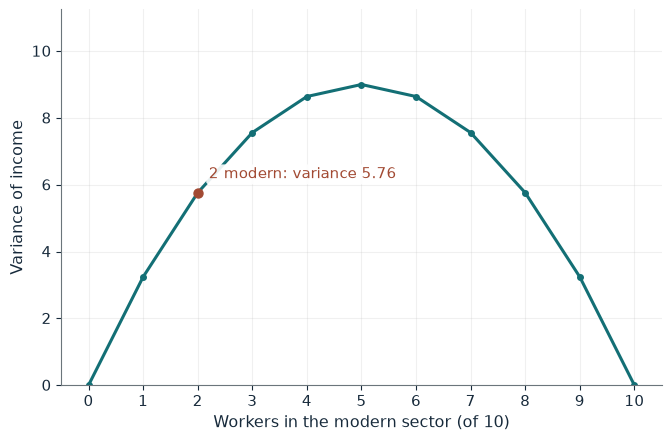

Modern workers                        2 of 10
Mean income                           3.20
Variance                              5.76
Peak variance for this modern income  9.00

Worked steps:
  1. Mean = (2 x 8 + 8 x 2) / 10 = 32 / 10 = 3.20
  2. Modern gap: 8 - 3.20 = 4.80; squared 23.0400
  3. Traditional gap: 2 - 3.20 = -1.20; squared 1.4400
  4. Sum = 2 x 23.0400 + 8 x 1.4400 = 57.60
  5. Variance = 57.60 / 10 = 5.76

Mean income = (2 x 8 + 8 x 2) / 10 = 3.20. Variance = (2 x (8 - 3.20)^2 + 8 x (2 - 3.20)^2) / 10 = 57.60 / 10 = 5.76. Inequality is still rising: each extra modern worker widens the spread.


In [2]:
show(kuznets_picture(m=2, ym=8))

Change one input, `m`, and hold the others at the book's values:

In [3]:
sweep(kuznets_picture, 'm', [0, 2, 5, 9], {'ym': 8}, ['Mean income', 'Variance'])

m | Mean income | Variance
0 | 2.00 | 0.00
2 | 3.20 | 5.76
5 | 5.00 | 9.00
9 | 7.40 | 3.24


The variance climbs from 0 to 5.76 and peaks at 9 when half the workers have moved, then falls to 3.24 with nine modern workers. Pure composition change traces an inverted U; it does not make one inevitable.

## 2. Structural transformation: where released farm workers go

Farm output stays at 280 while farm employment falls from 70 to 60; manufacturing produces 10 per worker.

$$Y_1=60\left(\frac{14}{3}\right)+40(10)=680$$

The within term is $0.70(14/3-4)\approx0.467$ and the reallocation term $\approx0.533$.

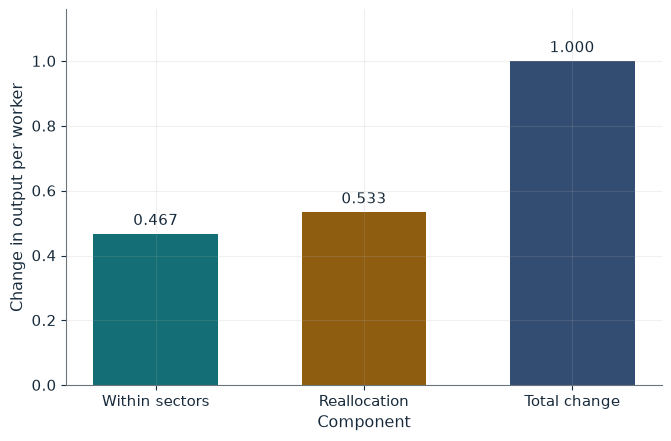

P0 before                     5.8
P1 after                      6.80
Within-sector term            0.467
Reallocation term             0.533
Total change                  1.000
Farm output per worker after  4.6667

Worked steps:
  1. Farm output per worker = 280 / 60 = 4.6667
  2. Y1 = 60 x 4.6667 + 40 x 10 = 280 + 400 = 680, so P1 = 680 / 100 = 6.80
  3. Within = 0.70 x (4.6667 - 4) + 0.30 x (10 - 10) = 0.467
  4. Reallocation = 4.6667 x (0.60 - 0.70) + 10 x (0.40 - 0.30) = 0.533
  5. Check: 0.467 + 0.533 = 1.000 = 6.80 - 5.8

10 farm workers are released and go to manufacturing at 10. Y1 = 60 x 4.6667 + 40 x 10 = 280 + 400 = 680, so aggregate productivity moves from 5.8 to 680 / 100 = 6.80. The change splits as 0.467 + 0.533 = 1.000: within sectors plus reallocation. Moving the released workers into higher-productivity jobs adds a positive reallocation term.


In [4]:
show(transformation_picture(dest='manufacturing', released=10))

Change one input, `dest`, and hold the others at the book's values:

In [5]:
sweep(transformation_picture, 'dest', ['manufacturing', 'informal'], {'released': 10}, ['P1 after', 'Within-sector term', 'Reallocation term'])

dest | P1 after | Within-sector term | Reallocation term
manufacturing | 6.80 | 0.467 | 0.533
informal | 6.10 | 0.467 | -0.167


Sending the released workers to informal services at 3 per worker gives $Y_1'=610$, so productivity still rises to 6.1, but the reallocation term turns negative.

## 3. Baumol cost disease: why concerts get dearer

The wage rises from 20 to 30 and the workshop goes from 2 to 4 devices per hour; a concert still takes 8 hours.

$$c_{P,1}=\frac{30}{4}=7.50, \qquad c_{S,1}=8(30)=240, \qquad \frac{240}{7.50}=32$$

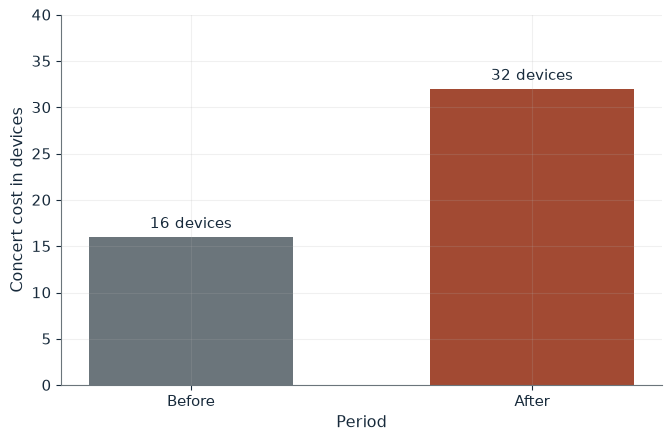

Device cost after      7.50
Device cost change     -25%
Concert cost after     240.00
Concert cost change    50%
Relative cost          16 to 32
Labor cost per ticket  1.33 to 2.00

Worked steps:
  1. Before: device = 20 / 2 = 10.00; concert = 8 x 20 = 160; relative = 160 / 10 = 16
  2. After: device = 30 / 4 = 7.50
  3. After: concert = 8 x 30 = 240
  4. Relative = 240 / 7.50 = 32
  5. Per ticket = 240 / 120 = 2.00, against 160 / 120 = 1.33

The device's labor cost moves from 10.00 to 30 / 4 = 7.50 (-25%), and the concert's from 160 to 8 x 30 = 240 (50%). The concert still uses 8 hours, yet its cost in devices rises from 16 to 32 because the workshop now makes 4 devices per hour. The labor cost per ticket goes from 1.33 to 2.00.


In [6]:
show(baumol_picture(prod=4, w1=30))

Change one input, `prod`, and hold the others at the book's values:

In [7]:
sweep(baumol_picture, 'prod', [2, 3, 4], {'w1': 30}, ['Device cost after', 'Concert cost after', 'Relative cost'])

prod | Device cost after | Concert cost after | Relative cost
2 | 15.00 | 240.00 | 16 to 16
3 | 10.00 | 240.00 | 16 to 24
4 | 7.50 | 240.00 | 16 to 32


The relative cost equals 8 times the workshop's productivity, so it doubles from 16 to 32 while the labor cost per ticket rises from 1.33 to 2.00.

## 4. Harris-Todaro: creating jobs that raise unemployment

Rural wage 100, city wage 200, jobs rise from 100 to 120. Migration stops when

$$100=\frac{120}{L_u}(200), \qquad L_u=240$$

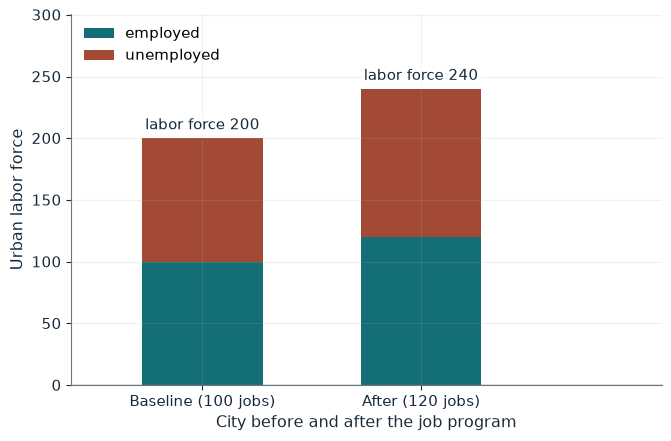

Urban labor force       240
Employed                120
Unemployed              120
Migrants                40
Change in unemployment  +20

Worked steps:
  1. Baseline: L_u = 100 x 200 / 100 = 200, unemployed 100
  2. On impact: p = 120 / 200 = 0.6000; expected wage 0.6000 x 200 = 120.00 against 100
  3. New equilibrium: L_u = 120 x 200 / 100 = 240
  4. Unemployed = 240 - 120 = 120
  5. Migrants = 240 - 200 = 40

Migration stops when the expected city wage equals the rural wage: L_u = 120 x 200 / 100 = 240, of whom 120 are employed and 120 unemployed. 20 new jobs draw 40 migrants, so unemployment rises by 20 even as employment rises by 20.


In [8]:
show(harris_picture(jobs=120, wu=200))

Change one input, `jobs`, and hold the others at the book's values:

In [9]:
sweep(harris_picture, 'jobs', [100, 120, 140], {'wu': 200}, ['Urban labor force', 'Unemployed', 'Migrants'])

jobs | Urban labor force | Unemployed | Migrants
100 | 200 | 100 | 0
120 | 240 | 120 | 40
140 | 280 | 140 | 80


Twenty jobs draw forty migrants: employment and unemployment each rise by 20, and the placement probability returns to one half.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

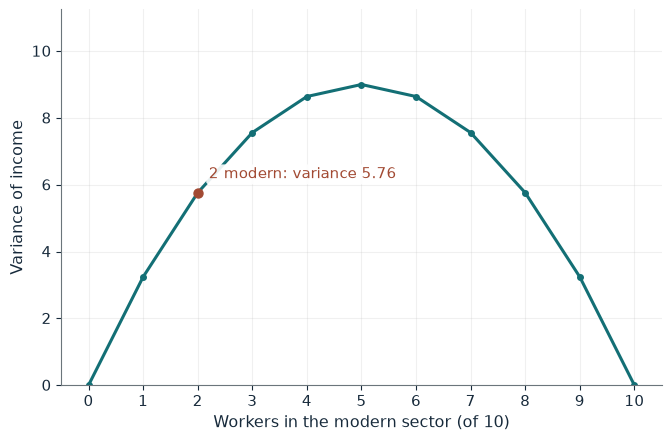

Modern workers                        2 of 10
Mean income                           3.20
Variance                              5.76
Peak variance for this modern income  9.00

Worked steps:
  1. Mean = (2 x 8 + 8 x 2) / 10 = 32 / 10 = 3.20
  2. Modern gap: 8 - 3.20 = 4.80; squared 23.0400
  3. Traditional gap: 2 - 3.20 = -1.20; squared 1.4400
  4. Sum = 2 x 23.0400 + 8 x 1.4400 = 57.60
  5. Variance = 57.60 / 10 = 5.76

Mean income = (2 x 8 + 8 x 2) / 10 = 3.20. Variance = (2 x (8 - 3.20)^2 + 8 x (2 - 3.20)^2) / 10 = 57.60 / 10 = 5.76. Inequality is still rising: each extra modern worker widens the spread.


In [10]:
show(kuznets_picture(m=2, ym=8))

## Practice

**1.** With 5 of 10 workers earning 8 and the rest 2, what is the variance of income?

<details><summary>Answer</summary>

Mean = (5 x 8 + 5 x 2) / 10 = 5; variance = (5 x 9 + 5 x 9) / 10 = 9.

</details>

**2.** What is the labor cost per concert ticket after the change, with 120 seats?

<details><summary>Answer</summary>

240 / 120 = 2.00, up from 160 / 120 = 1.33.

</details>

**3.** With 140 jobs at wage 200 and rural wage 100, what is urban unemployment?

<details><summary>Answer</summary>

L_u = 140 x 200 / 100 = 280, so unemployment is 280 - 140 = 140.

</details>